<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/05_instance_segmentation_app_cracks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧱 Application · Instance segmentation: finding cracks before they become disasters

**August 14, 2018, Genoa.** A 200-metre section of the Morandi bridge collapses, killing 43 people. Investigations
pointed to corrosion and cracks that inspections had not caught in time. Every year, engineers must inspect millions
of square metres of bridges, tunnels, dams, roads and buildings, often from ropes or cherry pickers.

Today, **drones** and **phones** take the pictures and computer vision finds the cracks. But a box is not enough: a
crack is long and thin, and engineers need its **exact shape** to measure its length and surface. That's
**instance segmentation**: for every object, a **pixel mask** (and its box and class).

```
 Classification        Detection             Semantic segmentation     Instance segmentation
 "there is a crack"    a box per object      a class per pixel         a mask per object (crack #1, crack #2…)
```

**A short history:** *Mask R-CNN* (Kaiming He et al., 2017) added a mask branch to a detector and became the
reference; *YOLACT* (2019) made it real time; the YOLO family then included segmentation heads (YOLOv8-seg, YOLO11-seg,
**YOLO26-seg**).

**Dataset:** *Crack-seg* (Ultralytics, ~4 000 photos of cracked concrete and asphalt with polygon masks).
**Your mission:** fine-tune YOLO26n-seg, then turn masks into an **inspection report** (crack area, length, severity).

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import os, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

os.environ["YOLO_VERBOSE"] = "False"          # quiet logs ("True" to watch every training step)
from ultralytics import YOLO
from ultralytics.utils import ASSETS, YAML
from ultralytics.utils.checks import check_yaml

DEVICE = get_device()
YOLO_DATA = DATA_DIR / "yolo_datasets"
WEIGHTS = DATA_DIR / "weights"
WEIGHTS.mkdir(exist_ok=True)


def yolo_dataset(yaml_name: str) -> Path:
    """Download an Ultralytics dataset into data/yolo_datasets/ and return a YAML pointing to it."""
    cfg = YAML.load(check_yaml(f"{yaml_name}.yaml"))
    folder = YOLO_DATA / Path(cfg["path"]).name
    if not folder.exists():
        url = cfg["download"]
        stem = Path(url).stem
        archive = download(url, YOLO_DATA / Path(url).name)
        tmp = extract(archive, YOLO_DATA / f"_tmp_{stem}")
        inner = tmp / stem if (tmp / stem).is_dir() else tmp
        shutil.move(str(inner), str(folder))
        shutil.rmtree(tmp, ignore_errors=True)
        archive.unlink()
    cfg["path"] = str(folder)
    cfg.pop("download", None)
    out = YOLO_DATA / f"{yaml_name}.yaml"
    YAML.save(out, cfg)
    return out

quest("Find cracks before they become disasters", chapter="Track 3 · Computer vision · Instance segmentation", xp=250)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Find cracks before they become disasters
   Track 3 · Computer vision · Instance segmentation
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Masks as polygons 🔍

For segmentation, each line of a YOLO label file is a **polygon**: the class id, then the (x, y) coordinates of its
vertices, normalised between 0 and 1:

```
class_id  x1 y1  x2 y2  x3 y3  ...
```

train  3717 images


val     200 images
test    112 images


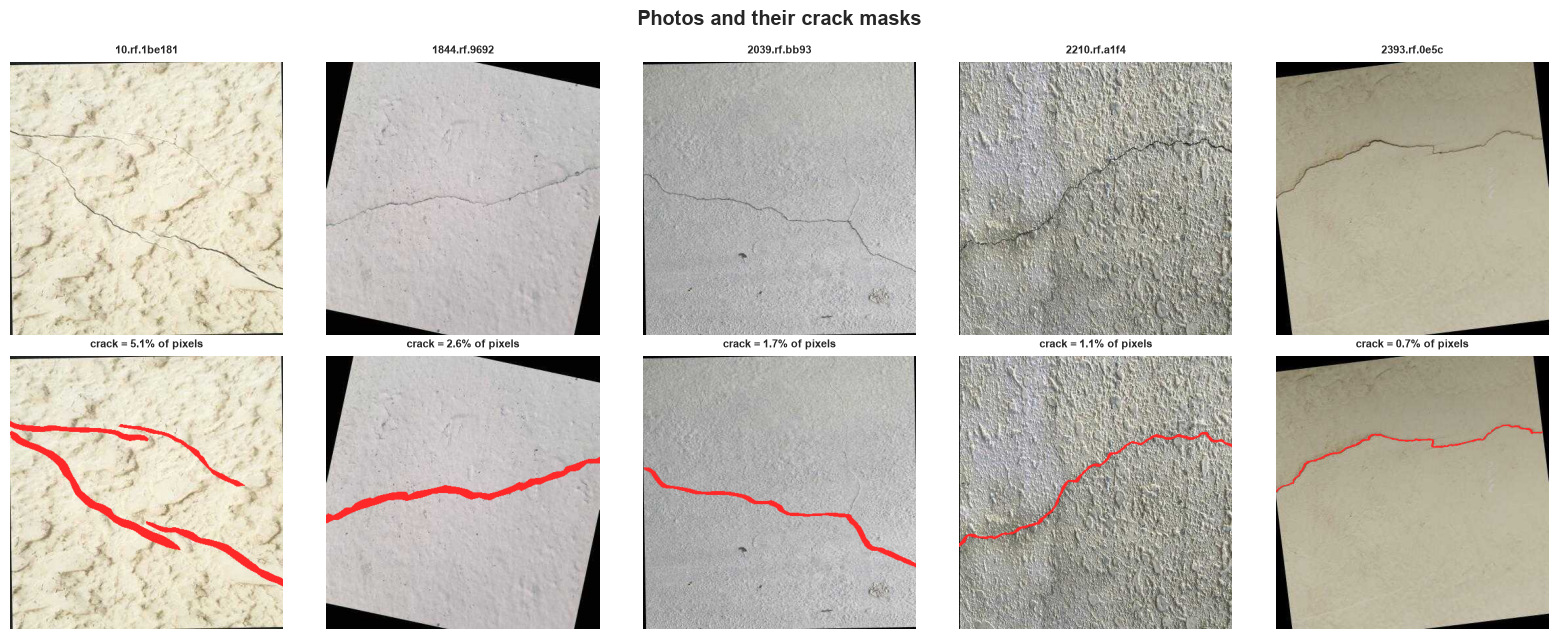

In [3]:
data_yaml = yolo_dataset("crack-seg")          # ~96 MB, downloaded once
root = YOLO_DATA / "crack-seg"
for split in ["train", "val", "test"]:
    print(f"{split:<5} {len(list((root / 'images' / split).glob('*.jpg'))):>5} images")


def polygon_mask(label_file, W, H):
    """Rasterise the polygons of a label file into one binary mask."""
    mask = np.zeros((H, W), np.uint8)
    for line in Path(label_file).read_text().splitlines():
        pts = np.array(line.split()[1:], float).reshape(-1, 2) * [W, H]
        cv2.fillPoly(mask, [pts.astype(np.int32)], 1)
    return mask


train_imgs = sorted((root / "images" / "train").glob("*.jpg"))
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for k, path in enumerate(train_imgs[::400][:5]):
    img = np.array(Image.open(path).convert("RGB")); H, W = img.shape[:2]
    m = polygon_mask(root / "labels" / "train" / f"{path.stem}.txt", W, H)
    axes[0, k].imshow(img); axes[0, k].set_title(path.stem[:12], fontsize=8)
    overlay = img.copy(); overlay[m == 1] = (255, 40, 40)
    axes[1, k].imshow(overlay); axes[1, k].set_title(f"crack = {100 * m.mean():.1f}% of pixels", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Photos and their crack masks", fontweight="bold"); plt.tight_layout(); plt.show()

Cracks usually cover **a few percent** of the pixels: thin, irregular, branching shapes, with shadows, stains and
joints that look similar. A hard problem.

## 2. Instance segmentation out of the box 🚌

A COCO-pretrained YOLO26n-seg already produces masks for 80 everyday classes:

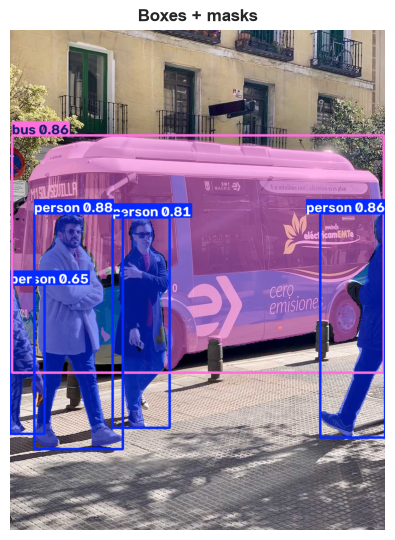

masks tensor: (5, 640, 480) → (objects, height, width)


In [4]:
seg_coco = YOLO(str(WEIGHTS / "yolo26n-seg.pt"))
r = seg_coco.predict(ASSETS / "bus.jpg", conf=0.3, device=DEVICE)[0]
plt.figure(figsize=(5, 6.5)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off"); plt.title("Boxes + masks"); plt.show()
print("masks tensor:", tuple(r.masks.data.shape), "→ (objects, height, width)")

## 3. Fine-tune YOLO26n-seg on cracks 🏋️

To keep the training around 10 minutes on a laptop GPU, we use 40% of the training images (`fraction=0.4`) and 8
epochs at 416 px. The model learns two things at once: boxes **and** masks, so it reports two families of metrics:
`box` mAP and `mask` mAP (IoU computed on pixels instead of boxes).

In [5]:
model = YOLO(str(WEIGHTS / "yolo26n-seg.pt"))
t0 = time.time()
metrics = model.train(data=str(data_yaml), epochs=8, imgsz=416, batch=16, fraction=0.4, device=DEVICE,
                      workers=NUM_WORKERS, project=str(RUNS_DIR / "cracks"), name="yolo26n-seg", exist_ok=True,
                      plots=False, deterministic=False, seed=SEED)
print(f"⏱️  {(time.time() - t0) / 60:.1f} min")
lb = Leaderboard("crack_seg", metric="val_mask_mAP50")
lb.add("YOLO26n-seg · 8 epochs · 40% data", metrics.seg.map50, box_mAP50=round(metrics.box.map50, 3),
       mask_mAP50_95=round(metrics.seg.map, 3))
lb.show()

⏱️  13.3 min
📋 YOLO26n-seg · 8 epochs · 40% data: val_mask_mAP50 = 0.69989


,,model,val_mask_mAP50,box_mAP50,mask_mAP50_95
rank,,,,,
1,🥇,YOLO26n-seg · 8 epochs · 40% data,0.69989,0.773,0.264


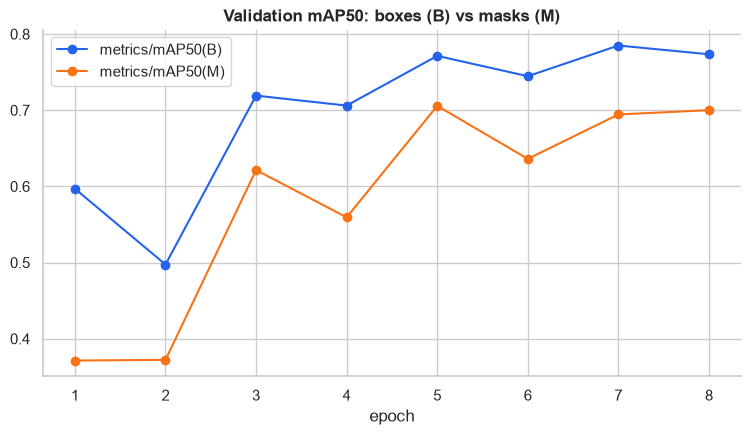

✅ Checkpoint · cracks/train (+60 XP)
   ██████████████░░░░░░░░░░ 60/100 XP


In [6]:
curves = pd.read_csv(Path(model.trainer.save_dir) / "results.csv")
curves.columns = curves.columns.str.strip()
curves.plot(x="epoch", y=["metrics/mAP50(B)", "metrics/mAP50(M)"], marker="o",
            title="Validation mAP50: boxes (B) vs masks (M)"); plt.show()
checkpoint("cracks/train", xp=60)

**Why is mask mAP lower than box mAP?** A box around a crack is easy to get "roughly right" (IoU ≥ 0.5), but a mask
must match a 5-pixel-wide shape pixel by pixel: one pixel off on each side and the IoU collapses. Thin objects are the
hardest case for segmentation metrics, which is why crack competitions often use F1 or Dice on pixels instead.

## 4. Test set predictions 🏁

🏁 Test · box mAP50 = 0.660 · mask mAP50 = 0.633


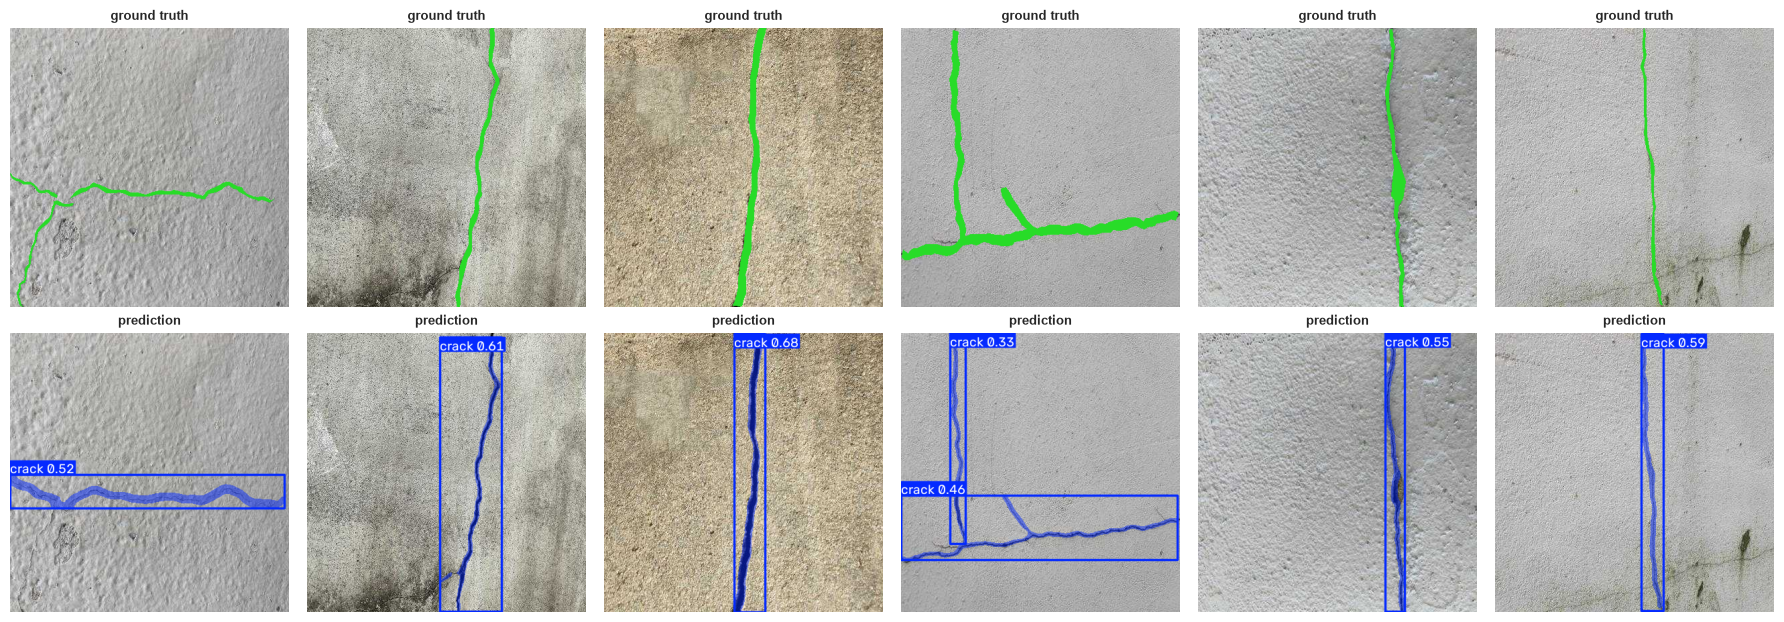

In [7]:
best = YOLO(str(Path(model.trainer.save_dir) / "weights" / "best.pt"))
test_metrics = best.val(data=str(data_yaml), split="test", imgsz=416, batch=16, device=DEVICE, plots=False,
                        project=str(RUNS_DIR / "cracks"), name="test", exist_ok=True)
print(f"🏁 Test · box mAP50 = {test_metrics.box.map50:.3f} · mask mAP50 = {test_metrics.seg.map50:.3f}")

test_imgs = sorted((root / "images" / "test").glob("*.jpg"))
picks = [test_imgs[i] for i in np.linspace(0, len(test_imgs) - 1, 6).astype(int)]
fig, axes = plt.subplots(2, 6, figsize=(18, 6.4))
for k, path in enumerate(picks):
    img = np.array(Image.open(path).convert("RGB")); H, W = img.shape[:2]
    gt = polygon_mask(root / "labels" / "test" / f"{path.stem}.txt", W, H)
    overlay = img.copy(); overlay[gt == 1] = (40, 220, 40)
    axes[0, k].imshow(overlay); axes[0, k].set_title("ground truth", fontsize=9)
    axes[1, k].imshow(best.predict(path, conf=0.25, imgsz=416, device=DEVICE)[0].plot()[..., ::-1])
    axes[1, k].set_title("prediction", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. From masks to an inspection report 📝

Masks are measurements. For each detected crack we compute:
- its **area** (number of mask pixels, and % of the photo),
- its **length**, approximated by the number of pixels of its *skeleton* (the mask thinned down to a 1-pixel line),
- its mean **width** ≈ area / length,
- a **severity** level from the width (in a real inspection, pixels are converted to millimetres with a reference
  object or the camera distance).

In [8]:
def skeleton_length(mask):
    """Morphological skeleton (pure OpenCV): repeatedly erode and keep what disappears."""
    mask = (mask > 0).astype(np.uint8)
    skel = np.zeros_like(mask)
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
    while mask.any():
        eroded = cv2.erode(mask, kernel)
        skel |= mask - cv2.dilate(eroded, kernel)
        mask = eroded
    return int(skel.sum())


rows = []
for path in test_imgs:
    r = best.predict(path, conf=0.25, imgsz=416, device=DEVICE, retina_masks=True)[0]
    if r.masks is None:
        rows.append(dict(image_id=path.stem, crack_id=0, area_px=0, area_pct=0.0, length_px=0, width_px=0.0))
        continue
    for k, (m, s) in enumerate(zip(r.masks.data.cpu().numpy(), r.boxes.conf.cpu().numpy()), start=1):
        area = int(m.sum()); length = max(skeleton_length(m), 1)
        rows.append(dict(image_id=path.stem, crack_id=k, confidence=round(float(s), 3), area_px=area,
                         area_pct=round(100 * area / m.size, 2), length_px=length, width_px=round(area / length, 1)))
report = pd.DataFrame(rows)
report["severity"] = pd.cut(report["width_px"], bins=[-1, 0.5, 4, 8, np.inf], labels=["none", "hairline", "moderate", "severe"])
make_submission(report.fillna({"confidence": 0}), "crack_inspection_report.csv")
print(report["severity"].value_counts().to_string())
report.sort_values("width_px", ascending=False).head(8)

📤 Submission saved: submissions/crack_inspection_report.csv  (138 rows, columns=['image_id', 'crack_id', 'confidence', 'area_px', 'area_pct', 'length_px', 'width_px', 'severity'])
severity
moderate    98
severe      29
hairline     6
none         5


,image_id,crack_id,confidence,area_px,area_pct,length_px,width_px,severity
97,3202.rf.e847435a50534b2273e1e2b8177f946e,1,0.769,8833,5.10,586,15.1,severe
53,2323.rf.06768caef93b3a44d3c59325a03230eb,1,0.723,8364,4.83,561,14.9,severe
136,3885.rf.5d0b08090bb3c2fcd3bc8fe36db9e51a,1,0.705,2096,1.21,159,13.2,severe
4,1706.rf.011d213c21ec78896c36728dcbc156f5,1,0.557,5867,3.39,497,11.8,severe
120,3443.rf.ae3196f72376757297122e81626f6f60,1,0.693,6214,3.59,532,11.7,severe
5,1706.rf.011d213c21ec78896c36728dcbc156f5,2,0.303,6396,3.70,562,11.4,severe
99,3207.rf.f408ffa769bb22f0cc56b51300ed9ce1,1,0.611,6165,3.56,559,11.0,severe
6,1716.rf.85ea38b36008beaa72c5d8541f734eb0,1,0.533,2107,1.22,196,10.8,severe


## 🏁 Mission accomplished

You trained a model that outlines cracks pixel by pixel and turned its masks into measurements an engineer can use.

### 🚀 Your turn (bonus XP)
1. Train on 100% of the data (`fraction=1.0`) and 20 epochs: how much does the mask mAP improve?
2. Increase `imgsz` to 640: thin cracks love resolution.
3. Compute a pixel-level F1/Dice between predicted and true masks on the test set (merge all instances per image).
4. Try `carparts-seg` (23 car parts, used for insurance damage assessment) with the same code.

In [9]:
checkpoint("cracks/complete", xp=140)
badge("Structure Inspector", "🧱")
progress()

✅ Checkpoint · cracks/complete (+140 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ████████████░░░░░░░░░░░░ 200/300 XP
╔════════════════════════════════════════╗
║ 🧱  BADGE UNLOCKED: Structure Inspector ║
╚════════════════════════════════════════╝
🐣 Data Explorer
████████████░░░░░░░░░░░░ 200/300 XP
Checkpoints unlocked: 2
Badges: 🧱 Structure Inspector
